# Sistemas lineales y Newton multivariable

Sistema lineal: A @ u = b. Newton: resolver J @ du = -F y actualizar u = u + du.

**Uso:** ejecuta los imports y el bloque del caso que necesites. Cada ejemplo empieza con sus propios datos. `def` se usa solo para expresiones matemáticas.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Sistema lineal

Fila = ecuación; columna = incógnita. Usar solve, no la inversa explícita.

In [2]:
A=np.array([[2.,1.],[1.,-1.]])
b=np.array([5.,1.])
u=np.linalg.solve(A,b)
print(u,'Residuo:',A@u-b)
assert np.allclose(A@u,b)

[2. 1.] Residuo: [0. 0.]


## 2. Newton — ejemplo de clase

F y J son expresiones matemáticas. J[i,j] deriva F[i] respecto de u[j]. Se corrige el signo negativo en J[1,1].

In [3]:
def F(u):
    x,y=u
    return np.array([y-np.cos(x),x-np.exp(y-1)])
def J(u):
    x,y=u
    return np.array([[np.sin(x),1.],[1.,-np.exp(y-1)]])
u=np.array([1.,1.])
tol=1e-9; max_iter=100
convergio=False
historial=[u.copy()]
for i in range(max_iter):
    Fu=F(u)
    if np.linalg.norm(Fu,np.inf)==0:
        convergio=True; break
    matriz=J(u)
    du=np.linalg.solve(matriz,-Fu)
    u=u+du
    historial.append(u.copy())
    if not np.all(np.isfinite(u)):
        break
    if np.linalg.norm(du,np.inf)<=tol and np.linalg.norm(F(u),np.inf)<=tol:
        convergio=True; break
raiz=u.copy()
print('Raíz:',raiz,'F:',F(raiz),'convergió:',convergio)
assert convergio and np.allclose(F(raiz),0,atol=tol)

Raíz: [0.75963732 0.72508582] F: [0. 0.] convergió: True


## 3. Comprobar Jacobiano — opcional

Ejecutar después del bloque 2. Diferencias centrales; comprobar signos y orden de variables.

In [4]:
u=raiz.copy()
h=1e-5
J_num=np.zeros((len(F(u)),len(u)))
for j in range(len(u)):
    e=np.zeros(len(u)); e[j]=h
    J_num[:,j]=(F(u+e)-F(u-e))/(2*h)
print('Analítico:',J(u),'Numérico:',J_num)
assert np.allclose(J_num,J(u),atol=1e-7)

Analítico: [[ 0.68865851  1.        ]
 [ 1.         -0.75963732]] Numérico: [[ 0.68865851  1.        ]
 [ 1.         -0.75963732]]


## 4. Gráfica de la solución

Ejecutar después del bloque 2. Las curvas deben cruzarse en la raíz.

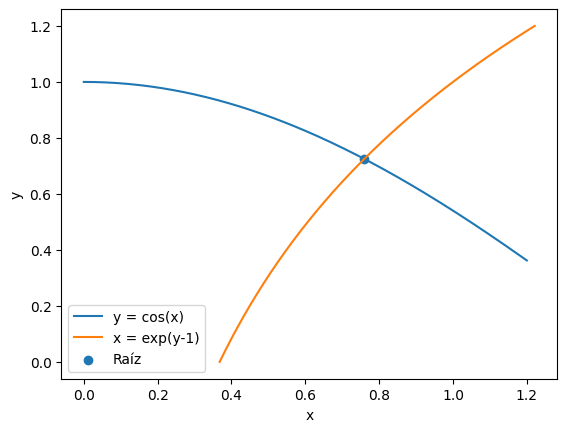

In [5]:
x=np.linspace(0,1.2,200); y=np.linspace(0,1.2,200)
plt.plot(x,np.cos(x),label='y = cos(x)')
plt.plot(np.exp(y-1),y,label='x = exp(y-1)')
plt.scatter(raiz[0],raiz[1],label='Raíz')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.show()

Material de estudio adaptado del notebook de clases y de la versión FC2_C2. Ejemplos de práctica; no son soluciones de las tareas. Comprueba las reglas de uso de material asistido por IA.